<a href="https://colab.research.google.com/github/ganeshchoudari09/DEEP_LEARNING/blob/main/DEEP_LEARNING/SKILLS/DL_SKILL_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ultralytics opencv-python matplotlib

In [2]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from collections import Counter

print("VisionPort Smart Classroom System Initialized!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
VisionPort Smart Classroom System Initialized!


In [3]:
model = YOLO("yolov8n.pt")

print("VisionPort Deep Learning Model Loaded Successfully!")

VisionPort Deep Learning Model Loaded Successfully!


In [4]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Image uploaded:", image_path)

Saving images.jpg to images.jpg
Image uploaded: images.jpg


In [5]:
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

print("Classroom Object Detection Completed!")


image 1/1 /content/images.jpg: 480x640 12 persons, 9 chairs, 3 laptops, 1 keyboard, 1 book, 424.0ms
Speed: 18.9ms preprocess, 424.0ms inference, 32.1ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict
Classroom Object Detection Completed!


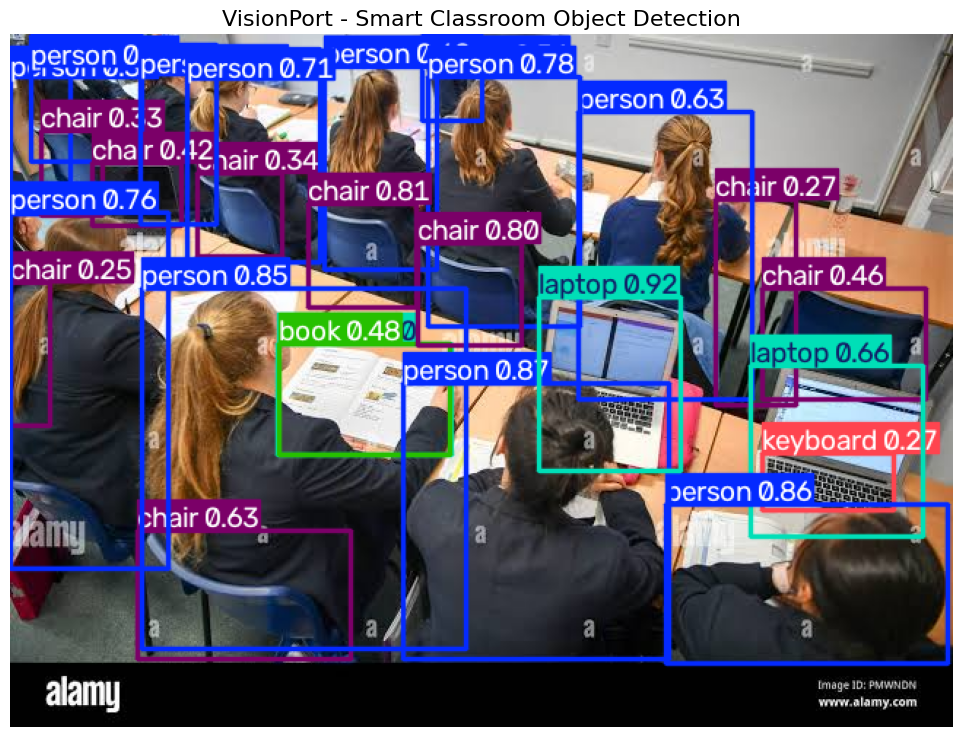

In [6]:
output_image = results[0].plot()

output_image = cv2.cvtColor(
    output_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(14, 9))

plt.imshow(output_image)

plt.axis("off")

plt.title(
    "VisionPort - Smart Classroom Object Detection",
    fontsize=16
)

plt.show()

In [7]:
print("=" * 50)
print("VISIONPORT - DETECTION REPORT")
print("=" * 50)

object_counts = Counter()

for box in results[0].boxes:

    class_id = int(box.cls[0])

    object_name = model.names[class_id]

    confidence = float(box.conf[0]) * 100

    object_counts[object_name] += 1

    print(
        "Object:", object_name,
        "| Confidence:", round(confidence, 2), "%"
    )

print("\nOBJECT SUMMARY")
print("-" * 30)

for name, count in object_counts.items():

    print(name, ":", count)

print("\nTotal Objects Detected:", sum(object_counts.values()))

print("=" * 50)

VISIONPORT - DETECTION REPORT
Object: laptop | Confidence: 92.18 %
Object: person | Confidence: 87.25 %
Object: person | Confidence: 85.71 %
Object: person | Confidence: 85.16 %
Object: chair | Confidence: 81.29 %
Object: chair | Confidence: 79.82 %
Object: person | Confidence: 78.14 %
Object: person | Confidence: 76.18 %
Object: person | Confidence: 70.91 %
Object: person | Confidence: 67.91 %
Object: laptop | Confidence: 66.19 %
Object: person | Confidence: 63.24 %
Object: chair | Confidence: 62.81 %
Object: person | Confidence: 58.71 %
Object: person | Confidence: 53.98 %
Object: book | Confidence: 48.2 %
Object: chair | Confidence: 46.16 %
Object: chair | Confidence: 42.07 %
Object: person | Confidence: 36.96 %
Object: chair | Confidence: 34.28 %
Object: chair | Confidence: 32.78 %
Object: person | Confidence: 31.14 %
Object: laptop | Confidence: 30.3 %
Object: keyboard | Confidence: 27.22 %
Object: chair | Confidence: 26.73 %
Object: chair | Confidence: 25.01 %

OBJECT SUMMARY
---

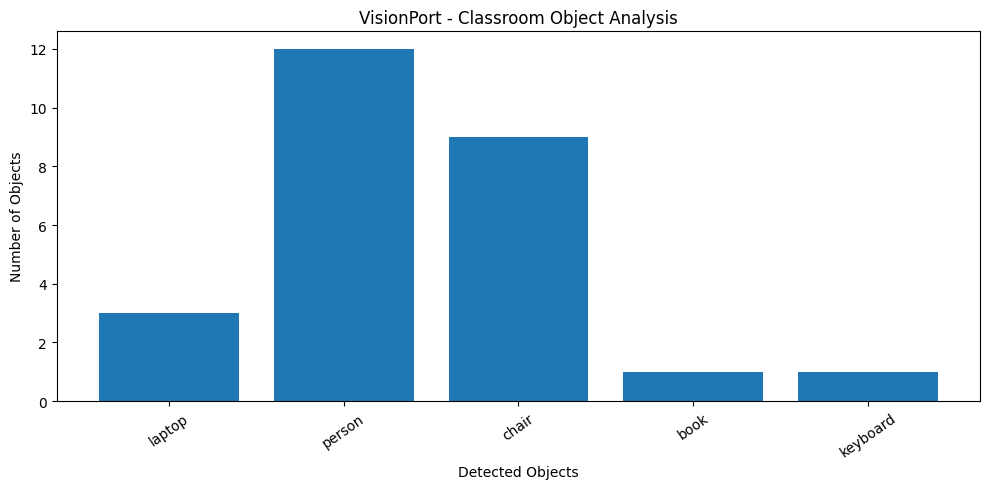

In [8]:
if object_counts:

    plt.figure(figsize=(10, 5))

    plt.bar(
        object_counts.keys(),
        object_counts.values()
    )

    plt.xlabel("Detected Objects")

    plt.ylabel("Number of Objects")

    plt.title("VisionPort - Classroom Object Analysis")

    plt.xticks(rotation=35)

    plt.tight_layout()

    plt.show()

else:
    print("No objects detected.")